# Work session 3: 
## Hypothesis spaces, feature representations and model generalization

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Part A : Exploring different hypothesis spaces 

## Step 1: Explore the dataset

### 1- Load the dataset into a DataFrame

In [42]:
df = pd.DataFrame({
    "Student": [f"S{i}" for i in range(1, 11)],
    "Hours":   [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Score":   [42, 48, 55, 59, 66, 70, 78, 81, 89, 91]
})
print(df)

  Student  Hours  Score
0      S1      1     42
1      S2      2     48
2      S3      3     55
3      S4      4     59
4      S5      5     66
5      S6      6     70
6      S7      7     78
7      S8      8     81
8      S9      9     89
9     S10     10     91


### 2- Dimensions + descriptive statistics

In [43]:
print("Shape:", df.shape)
print("\nDataFrame Description: \n", df.describe())

Shape: (10, 3)

DataFrame Description: 
           Hours      Score
count  10.00000  10.000000
mean    5.50000  67.900000
std     3.02765  16.907921
min     1.00000  42.000000
25%     3.25000  56.000000
50%     5.50000  68.000000
75%     7.75000  80.250000
max    10.00000  91.000000


##### Ok, Now I understand The Dataset

### 3- Scatter plot

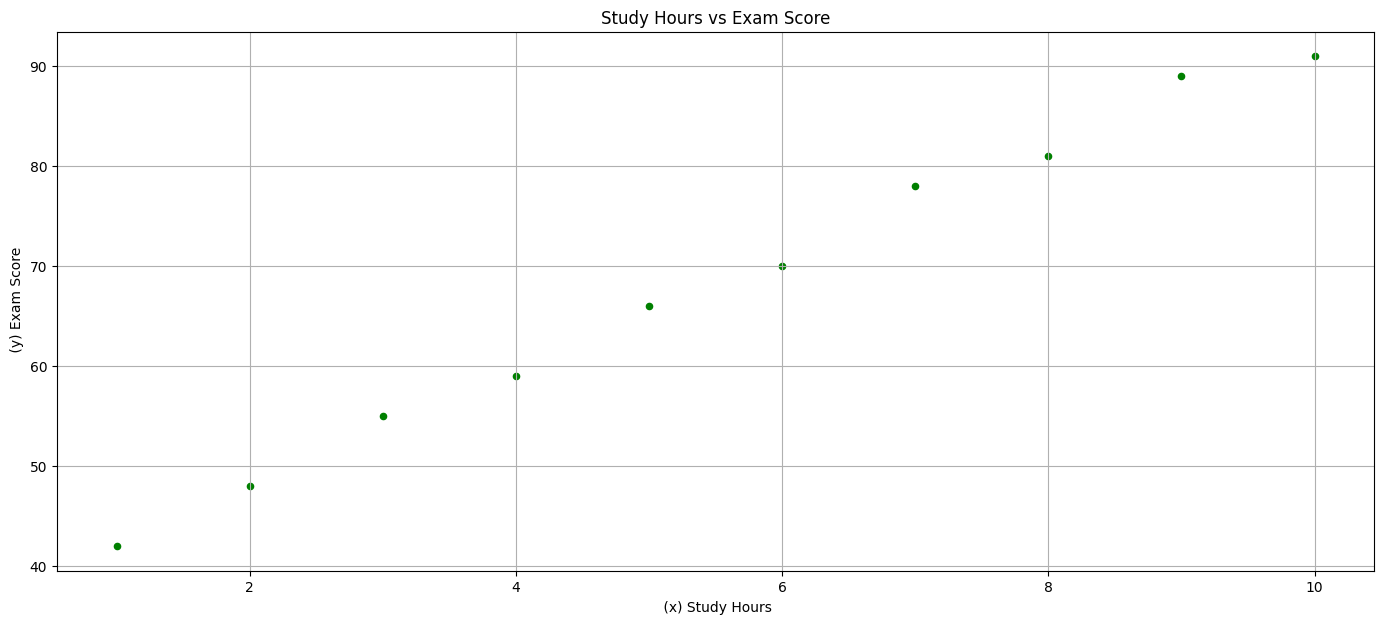

In [44]:
df.plot(
    kind="scatter",
    title="Study Hours vs Exam Score",
    x="Hours",
    y="Score",
    color="Green",
    figsize=(17, 7),
    grid=True,
    xlabel=" (x) Study Hours",
    ylabel=" (y) Exam Score"
)
plt.show()

- The points are almost aligned on a **straight rising line**
  - more study hours means --> higher score.
- This suggests a **near-linear relationship**, so I expect a simple model to work well.


### 4- Prepare X and y

In [45]:
X = df[["Hours"]]   # double brackets → DataFrame (2D)
y = df["Score"]     # Series (1D)

## Step 2: Fit the 6 models

In [46]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor

### 5- Dictionary of the six models

In [47]:
models = {
    "Linear Regression": LinearRegression(),

    "Polynomial (degree 2)": Pipeline([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("reg",  LinearRegression())
    ]),

    "Polynomial (degree 3)": Pipeline([
        ("poly", PolynomialFeatures(degree=3, include_bias=False)),
        ("reg",  LinearRegression())
    ]),

    "Decision Tree (depth 1)": DecisionTreeRegressor(max_depth=1, random_state=42),
    "Decision Tree (depth 3)": DecisionTreeRegressor(max_depth=3, random_state=42),

    "KNN (k = 3)": KNeighborsRegressor(n_neighbors=3)
}


### 6- Fit each model on the full dataset

In [48]:
for name, model in models.items():
    model.fit(X, y)
    print(f"{name} -> fitted ✔")

Linear Regression -> fitted ✔
Polynomial (degree 2) -> fitted ✔
Polynomial (degree 3) -> fitted ✔
Decision Tree (depth 1) -> fitted ✔
Decision Tree (depth 3) -> fitted ✔
KNN (k = 3) -> fitted ✔


## Step 3: Compare the models

In [49]:
from sklearn.metrics import mean_squared_error, r2_score

### 1- Plot all models

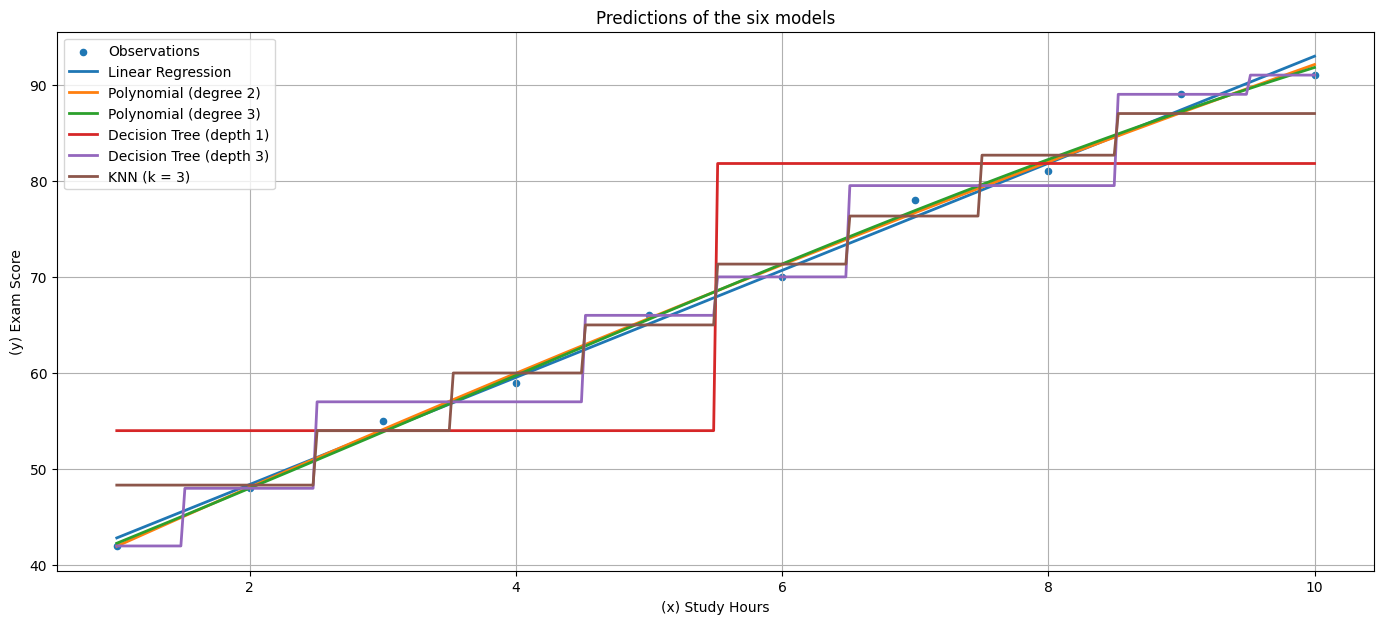

In [50]:
x_grid = pd.DataFrame({"Hours": np.linspace(1, 10, 300)})

ax = df.plot(
    kind="scatter", x="Hours", y="Score",
    title="Predictions of the six models",
    xlabel="(x) Study Hours", ylabel="(y) Exam Score",
    figsize=(17, 7),
    grid=True,
    legend=True,
    label="Observations"
)

for name, model in models.items():
    ax.plot(x_grid["Hours"], model.predict(x_grid), label=name, linewidth=2)

plt.legend()
plt.show()

### 2- Training RMSE and R²

In [51]:
results = []
for name, model in models.items():
    y_pred = model.predict(X)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    r2   = r2_score(y, y_pred)
    results.append([name, rmse, r2])

results_A = pd.DataFrame(results, columns=["Model", "Training RMSE", "Training R²"])
print(results_A.round(4).to_string(index=False))

                  Model  Training RMSE  Training R²
      Linear Regression         1.1672       0.9947
  Polynomial (degree 2)         1.0435       0.9958
  Polynomial (degree 3)         1.0211       0.9959
Decision Tree (depth 1)         8.0050       0.7509
Decision Tree (depth 3)         1.1180       0.9951
            KNN (k = 3)         2.6562       0.9726


## Part B : Investigating model complexity and generalization  
## Step 1: Leave-One-Out (LOOCV)

In [52]:
from sklearn.model_selection import LeaveOneOut

loo = LeaveOneOut()
print("Number of iterations:", loo.get_n_splits(X))

for i, (train_idx, test_idx) in enumerate(loo.split(X), start=1):
    print(f"\n--- Iteration {i} ---")
    print("Train indices:", train_idx)
    print("Test index   :", test_idx)
    print("Train Hours  :", X.iloc[train_idx]["Hours"].tolist())
    print("Test Hours   :", X.iloc[test_idx]["Hours"].tolist(),
          "| Test Score:", y.iloc[test_idx].tolist())

Number of iterations: 10

--- Iteration 1 ---
Train indices: [1 2 3 4 5 6 7 8 9]
Test index   : [0]
Train Hours  : [2, 3, 4, 5, 6, 7, 8, 9, 10]
Test Hours   : [1] | Test Score: [42]

--- Iteration 2 ---
Train indices: [0 2 3 4 5 6 7 8 9]
Test index   : [1]
Train Hours  : [1, 3, 4, 5, 6, 7, 8, 9, 10]
Test Hours   : [2] | Test Score: [48]

--- Iteration 3 ---
Train indices: [0 1 3 4 5 6 7 8 9]
Test index   : [2]
Train Hours  : [1, 2, 4, 5, 6, 7, 8, 9, 10]
Test Hours   : [3] | Test Score: [55]

--- Iteration 4 ---
Train indices: [0 1 2 4 5 6 7 8 9]
Test index   : [3]
Train Hours  : [1, 2, 3, 5, 6, 7, 8, 9, 10]
Test Hours   : [4] | Test Score: [59]

--- Iteration 5 ---
Train indices: [0 1 2 3 5 6 7 8 9]
Test index   : [4]
Train Hours  : [1, 2, 3, 4, 6, 7, 8, 9, 10]
Test Hours   : [5] | Test Score: [66]

--- Iteration 6 ---
Train indices: [0 1 2 3 4 6 7 8 9]
Test index   : [5]
Train Hours  : [1, 2, 3, 4, 5, 7, 8, 9, 10]
Test Hours   : [6] | Test Score: [70]

--- Iteration 7 ---
Train indice

- 9 students for training and 1 for testing.
- Each student is the test set **exactly once**, and the test student is never seen during training.


## Step 02 : Polynomial degrees + LOOCV

### 1-

In [53]:
from sklearn.model_selection import cross_val_score

degrees = [1, 2, 3, 5, 9]
loo = LeaveOneOut()
rows = []

for d in degrees:
    model = Pipeline([
        ("poly", PolynomialFeatures(degree=d, include_bias=False)),
        ("reg",  LinearRegression())
    ])

    # Training RMSE (fit on the full dataset)
    model.fit(X, y)
    train_rmse = np.sqrt(mean_squared_error(y, model.predict(X)))

    # LOOCV RMSE
    scores = cross_val_score(model, X, y, cv=loo,
                             scoring="neg_mean_squared_error")
    loocv_rmse = np.sqrt(-scores.mean())

    rows.append([d, train_rmse, loocv_rmse])

results_B = pd.DataFrame(rows, columns=["Polynomial Degree", "Training RMSE", "LOOCV RMSE"])
print(results_B.round(4).to_string(index=False))


 Polynomial Degree  Training RMSE  LOOCV RMSE
                 1         1.1672      1.5486
                 2         1.0435      1.5728
                 3         1.0211      2.0620
                 5         0.8943      3.7070
                 9         0.0002    261.9061


### 2- Best degree = lowest LOOCV RMSE 

In [54]:
best = results_B.loc[results_B["LOOCV RMSE"].idxmin()]
print("\nBest degree:", int(best["Polynomial Degree"]),
      "| LOOCV RMSE =", round(best["LOOCV RMSE"], 4))


Best degree: 1 | LOOCV RMSE = 1.5486


- The best degree is **1** ( **LOOCV RMSE = 1.5486**).
- The data is almost linear, so adding curvature only adds variance without reducing the real error.

### 3- Plot: Training RMSE vs LOOCV RMSE

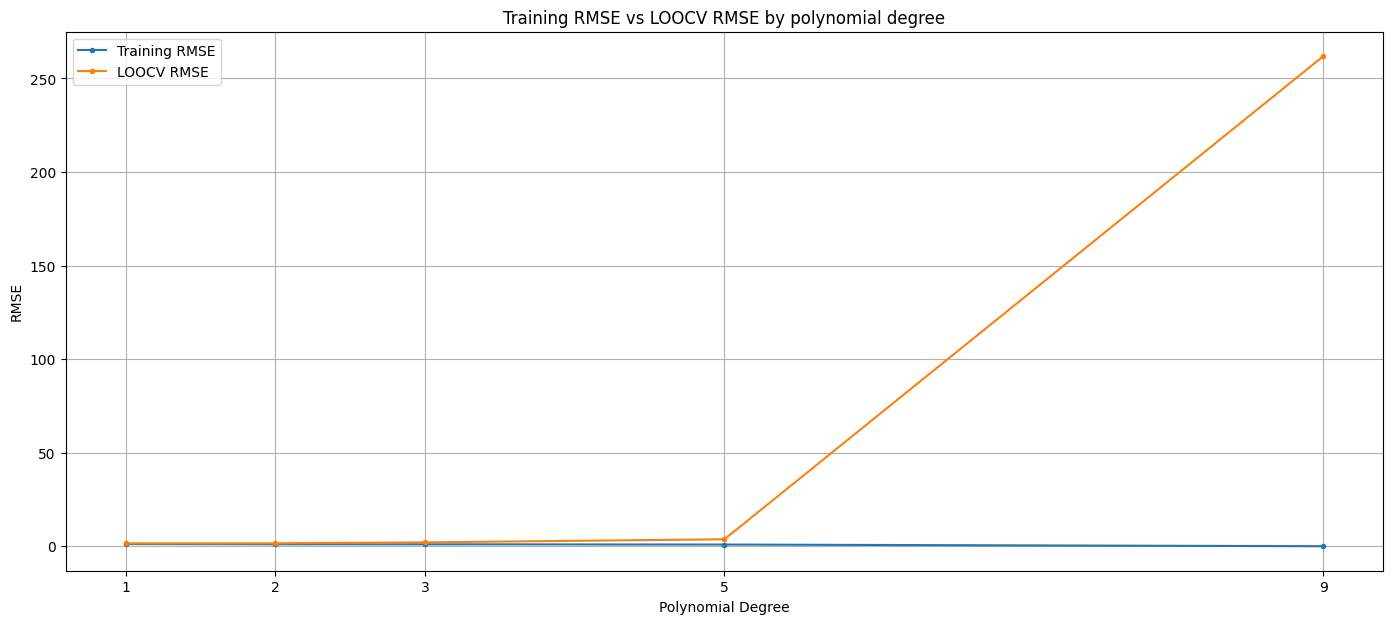

In [55]:
ax = results_B.plot(
    kind="line", marker=".", figsize=(17, 7), grid=True,
    title="Training RMSE vs LOOCV RMSE by polynomial degree",
    x="Polynomial Degree", y=["Training RMSE", "LOOCV RMSE"],
    xlabel="Polynomial Degree", ylabel="RMSE"
)
ax.set_xticks(degrees)
plt.show()

## Part C : Investigating feature representation and regularization  

## Step 1: Compare feature representations

In [56]:
from sklearn.preprocessing import StandardScaler

### 1- Helper function: LOOCV RMSE for any model (we will reuse it later)

In [57]:
def loocv_rmse(model, X, y):
    scores = cross_val_score(model, X, y, cv=LeaveOneOut(),
                             scoring="neg_mean_squared_error")
    return np.sqrt(-scores.mean())

### 2- Helper function: Training RMSE

In [58]:
def train_rmse(model, X, y):
    model.fit(X, y)
    return np.sqrt(mean_squared_error(y, model.predict(X)))

### 3- Three feature representations (Pipeline = transform + scale + regress)

In [59]:
representations = {
    "Original (x)":            1,
    "Polynomial (x ... x³)":   3,
    "Polynomial (x ... x⁵)":   5,
}

rows = []
for name, d in representations.items():
    model = Pipeline([
        ("poly",   PolynomialFeatures(degree=d, include_bias=False)),
        ("scaler", StandardScaler()),
        ("reg",    LinearRegression())
    ])
    rows.append([name, d, train_rmse(model, X, y), loocv_rmse(model, X, y)])

results_C1 = pd.DataFrame(rows, columns=["Representation", "Degree",
                                         "Training RMSE", "LOOCV RMSE"])
print(results_C1.round(4).to_string(index=False))

       Representation  Degree  Training RMSE  LOOCV RMSE
         Original (x)       1         1.1672      1.5486
Polynomial (x ... x³)       3         1.0211      2.0620
Polynomial (x ... x⁵)       5         0.8943      3.7070


### 4- Plot

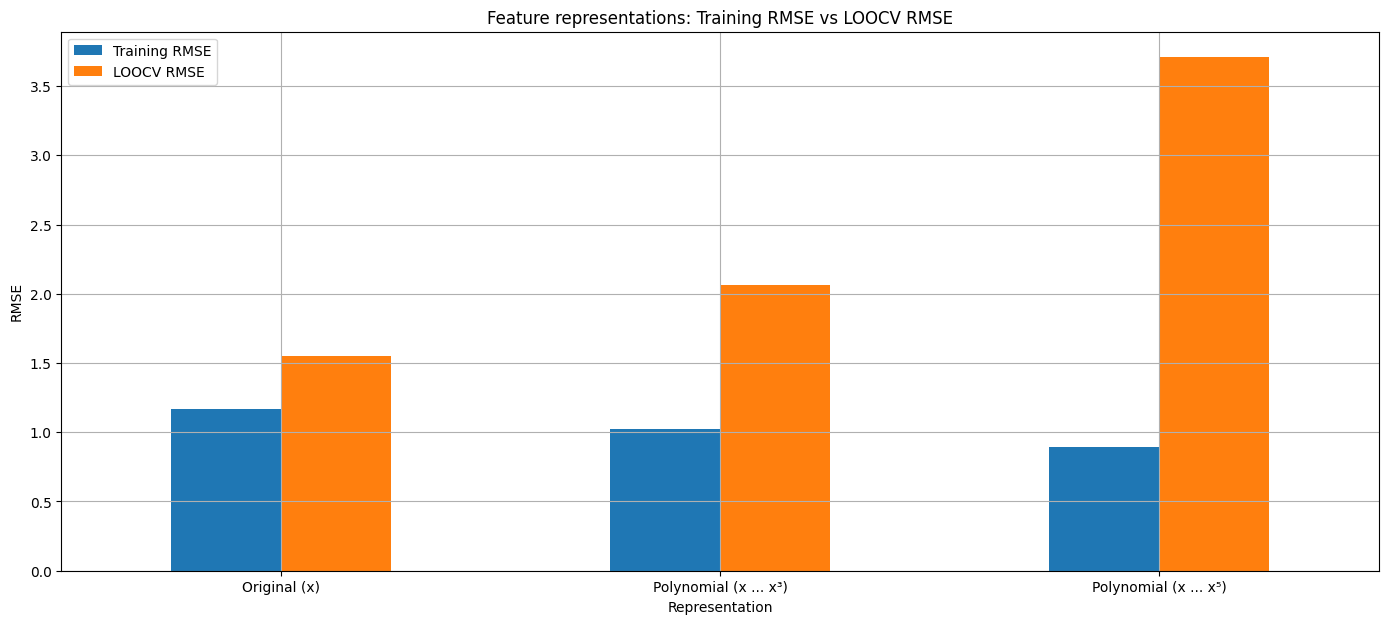

In [60]:
ax = results_C1.plot(
    kind="bar", figsize=(17, 7), grid=True, rot=0,
    title="Feature representations: Training RMSE vs LOOCV RMSE",
    x="Representation", y=["Training RMSE", "LOOCV RMSE"],
    ylabel="RMSE"
)
plt.show()

## Step 2: Regularization (Ridge & Lasso)

### 1-

In [61]:
from sklearn.linear_model import Ridge, Lasso

alphas = [0.01, 0.1, 1, 10]
rows = []

for alpha in alphas:
    for reg_name, reg in [("Ridge (L2)", Ridge(alpha=alpha)),
                          ("Lasso (L1)", Lasso(alpha=alpha, max_iter=100000))]:
        model = Pipeline([
            ("poly",   PolynomialFeatures(degree=5, include_bias=False)),
            ("scaler", StandardScaler()),
            ("reg",    reg)
        ])
        rows.append([reg_name, alpha,
                     train_rmse(model, X, y),
                     loocv_rmse(model, X, y)])

results_C2 = pd.DataFrame(rows, columns=["Model", "Alpha",
                                         "Training RMSE", "LOOCV RMSE"])
print(results_C2.round(4).to_string(index=False))


     Model  Alpha  Training RMSE  LOOCV RMSE
Ridge (L2)   0.01         1.0011      2.1442
Lasso (L1)   0.01         1.0048      1.7654
Ridge (L2)   0.10         1.0865      1.8071
Lasso (L1)   0.10         1.0656      1.6223
Ridge (L2)   1.00         2.2175      3.5735
Lasso (L1)   1.00         1.5370      1.9187
Ridge (L2)  10.00         5.5621      7.2820
Lasso (L1)  10.00        10.0679     11.8773


### 2- Best alpha for each model (lowest LOOCV RMSE)

In [62]:
best_reg = results_C2.loc[results_C2.groupby("Model")["LOOCV RMSE"].idxmin()]
print("\nBest alpha per model:")
print(best_reg.round(4).to_string(index=False))


Best alpha per model:
     Model  Alpha  Training RMSE  LOOCV RMSE
Lasso (L1)    0.1         1.0656      1.6223
Ridge (L2)    0.1         1.0865      1.8071


### 3- Plot: LOOCV RMSE vs alpha

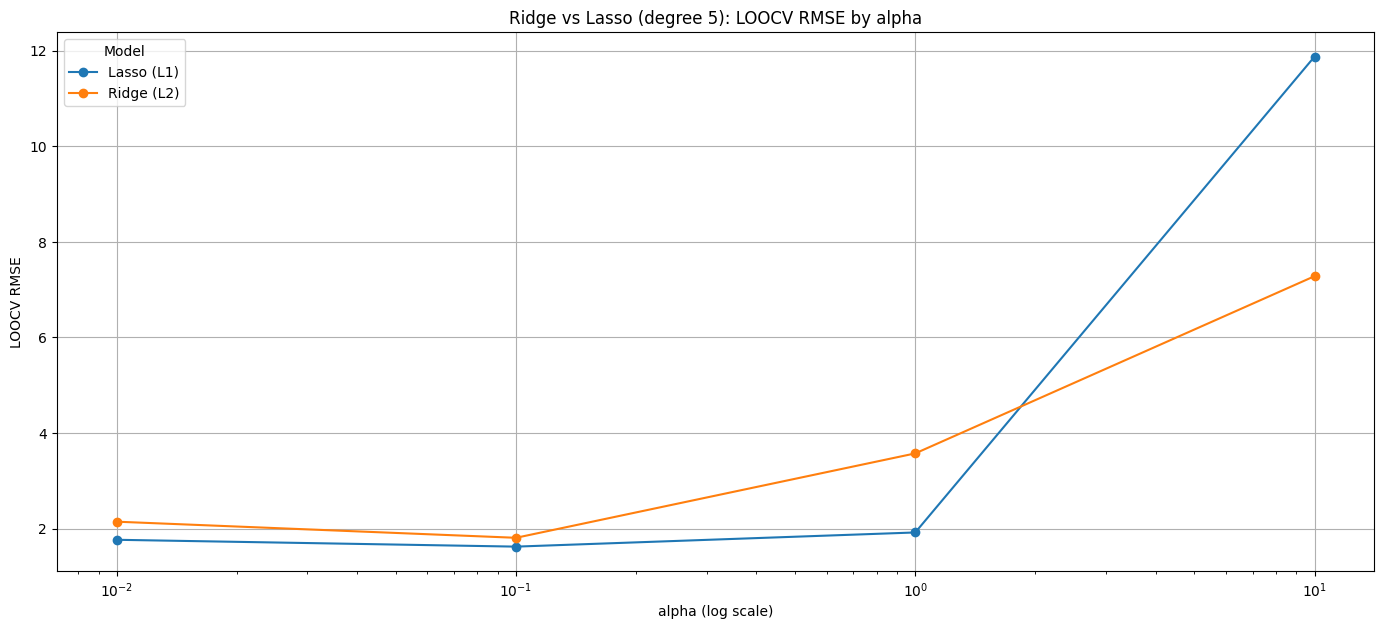

In [63]:
ax = results_C2.pivot(index="Alpha", columns="Model", values="LOOCV RMSE").plot(
    kind="line", marker="o", figsize=(17, 7), grid=True, logx=True,
    title="Ridge vs Lasso (degree 5): LOOCV RMSE by alpha",
    xlabel="alpha (log scale)", ylabel="LOOCV RMSE"
)
plt.show()

## Step 3: Full Table (All 8 Models)

### 1- Best alpha for Ridge and Lasso (from Step 2)

In [64]:
best_ridge_alpha = results_C2[results_C2["Model"] == "Ridge (L2)"] \
    .loc[lambda d: d["LOOCV RMSE"].idxmin(), "Alpha"]
best_lasso_alpha = results_C2[results_C2["Model"] == "Lasso (L1)"] \
    .loc[lambda d: d["LOOCV RMSE"].idxmin(), "Alpha"]

print("Best Ridge alpha:", best_ridge_alpha)
print("Best Lasso alpha:", best_lasso_alpha)

def poly_pipe(degree, reg):
    return Pipeline([
        ("poly",   PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("reg",    reg)
    ])


Best Ridge alpha: 0.1
Best Lasso alpha: 0.1


### 2- (Model, Feature, Regularization, estimator)

In [65]:
table_models = [
    ("Linear Regression",     "Degree 1", "None", poly_pipe(1, LinearRegression())),
    ("Polynomial Regression", "Degree 3", "None", poly_pipe(3, LinearRegression())),
    ("Polynomial Regression", "Degree 5", "None", poly_pipe(5, LinearRegression())),
    ("Ridge Regression",      "Degree 5", "L2",   poly_pipe(5, Ridge(alpha=best_ridge_alpha))),
    ("Lasso Regression",      "Degree 5", "L1",   poly_pipe(5, Lasso(alpha=best_lasso_alpha, max_iter=100000))),
    ("Decision Tree",         "depth 1",  "None", DecisionTreeRegressor(max_depth=1, random_state=42)),
    ("Decision Tree",         "depth 3",  "None", DecisionTreeRegressor(max_depth=3, random_state=42)),
    ("KNN",                   "k = 3",    "None", KNeighborsRegressor(n_neighbors=3)),
]

rows = []
for model_name, feat, regu, est in table_models:
    rows.append([model_name, feat, regu, loocv_rmse(est, X, y)])

results_C3 = pd.DataFrame(rows, columns=["Model", "Feature / Degree",
                                         "Regularization", "LOOCV RMSE"])
print(results_C3.round(4).to_string(index=False))


                Model Feature / Degree Regularization  LOOCV RMSE
    Linear Regression         Degree 1           None      1.5486
Polynomial Regression         Degree 3           None      2.0620
Polynomial Regression         Degree 5           None      3.7070
     Ridge Regression         Degree 5             L2      1.8071
     Lasso Regression         Degree 5             L1      1.6223
        Decision Tree          depth 1           None     13.4583
        Decision Tree          depth 3           None      6.3659
                  KNN            k = 3           None      6.0037


### 3- Does regularization help Poly 5?

In [66]:
poly5   = results_C3.iloc[2]["LOOCV RMSE"]
ridge5  = results_C3.iloc[3]["LOOCV RMSE"]
lasso5  = results_C3.iloc[4]["LOOCV RMSE"]
print(f"\nPoly5 = {poly5:.4f} | Ridge5 = {ridge5:.4f} | Lasso5 = {lasso5:.4f}")
print("Ridge improves Poly5 ?", ridge5 < poly5)
print("Lasso improves Poly5 ?", lasso5 < poly5)


Poly5 = 3.7070 | Ridge5 = 1.8071 | Lasso5 = 1.6223
Ridge improves Poly5 ? True
Lasso improves Poly5 ? True


## Part D : Final model comparison  

## Step 01 : Pick the best configuration of each family

### 1- Polynomial: best degree among 2, 3, 5, 9 (degree 1 is already "Linear Regression")

In [67]:
poly_scores = {d: loocv_rmse(poly_pipe(d, LinearRegression()), X, y) for d in [2, 3, 5, 9]}
best_poly_deg = min(poly_scores, key=poly_scores.get)

### 2- Decision Tree: best depth among 1, 3

In [68]:
tree_scores = {k: loocv_rmse(DecisionTreeRegressor(max_depth=k, random_state=42), X, y) for k in [1, 3]}
best_tree_depth = min(tree_scores, key=tree_scores.get)

print("Best Polynomial degree :", best_poly_deg)
print("Best Ridge alpha       :", best_ridge_alpha)
print("Best Lasso alpha       :", best_lasso_alpha)
print("Best Tree depth        :", best_tree_depth)

Best Polynomial degree : 2
Best Ridge alpha       : 0.1
Best Lasso alpha       : 0.1
Best Tree depth        : 3


## Step 02 :Final models

In [69]:
final_models = {
    "Linear Regression":                 poly_pipe(1, LinearRegression()),
    f"Polynomial (deg {best_poly_deg})":  poly_pipe(best_poly_deg, LinearRegression()),
    f"Ridge (deg 5, α={best_ridge_alpha})": poly_pipe(5, Ridge(alpha=best_ridge_alpha)),
    f"Lasso (deg 5, α={best_lasso_alpha})": poly_pipe(5, Lasso(alpha=best_lasso_alpha, max_iter=100000)),
    f"Decision Tree (depth {best_tree_depth})":
        DecisionTreeRegressor(max_depth=best_tree_depth, random_state=42),
    "KNN (k = 3)":                       KNeighborsRegressor(n_neighbors=3),
}

## Step 03: Summary table

In [70]:
rows = []
for name, model in final_models.items():
    tr = train_rmse(model, X, y)
    cv = loocv_rmse(model, X, y)
    rows.append([name, tr, cv, cv - tr])

final_table = pd.DataFrame(rows, columns=["Model", "Training RMSE", "LOOCV RMSE", "Gap (LOOCV - Train)"])
final_table = final_table.sort_values("LOOCV RMSE").reset_index(drop=True)
print(final_table.round(4).to_string(index=False))

best_model = final_table.iloc[0]
print(f"\nBest generalization: {best_model['Model']} | LOOCV RMSE = {best_model['LOOCV RMSE']:.4f}")


                  Model  Training RMSE  LOOCV RMSE  Gap (LOOCV - Train)
      Linear Regression         1.1672      1.5486               0.3814
     Polynomial (deg 2)         1.0435      1.5728               0.5293
   Lasso (deg 5, α=0.1)         1.0656      1.6223               0.5567
   Ridge (deg 5, α=0.1)         1.0865      1.8071               0.7206
            KNN (k = 3)         2.6562      6.0037               3.3475
Decision Tree (depth 3)         1.1180      6.3659               5.2479

Best generalization: Linear Regression | LOOCV RMSE = 1.5486


## Step 04 : Comparative plot: fitted predictions

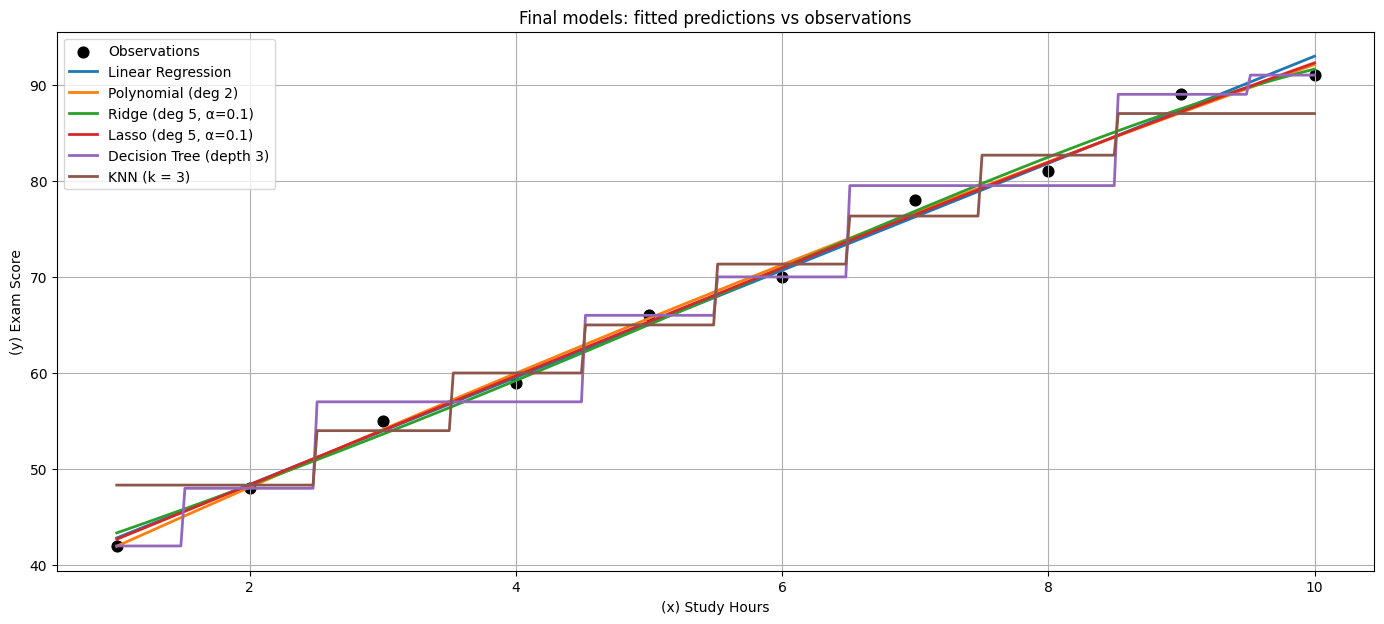

In [71]:
x_grid = pd.DataFrame({"Hours": np.linspace(1, 10, 300)})

ax = df.plot(
    kind="scatter", x="Hours", y="Score",
    color="black", s=60, figsize=(17, 7), grid=True,
    title="Final models: fitted predictions vs observations",
    xlabel="(x) Study Hours", ylabel="(y) Exam Score",
    label="Observations"
)
for name, model in final_models.items():
    ax.plot(x_grid["Hours"], model.predict(x_grid), label=name, linewidth=2)
ax.legend()
plt.show()

## Step 05: Comparative plot: Training vs LOOCV RMSE

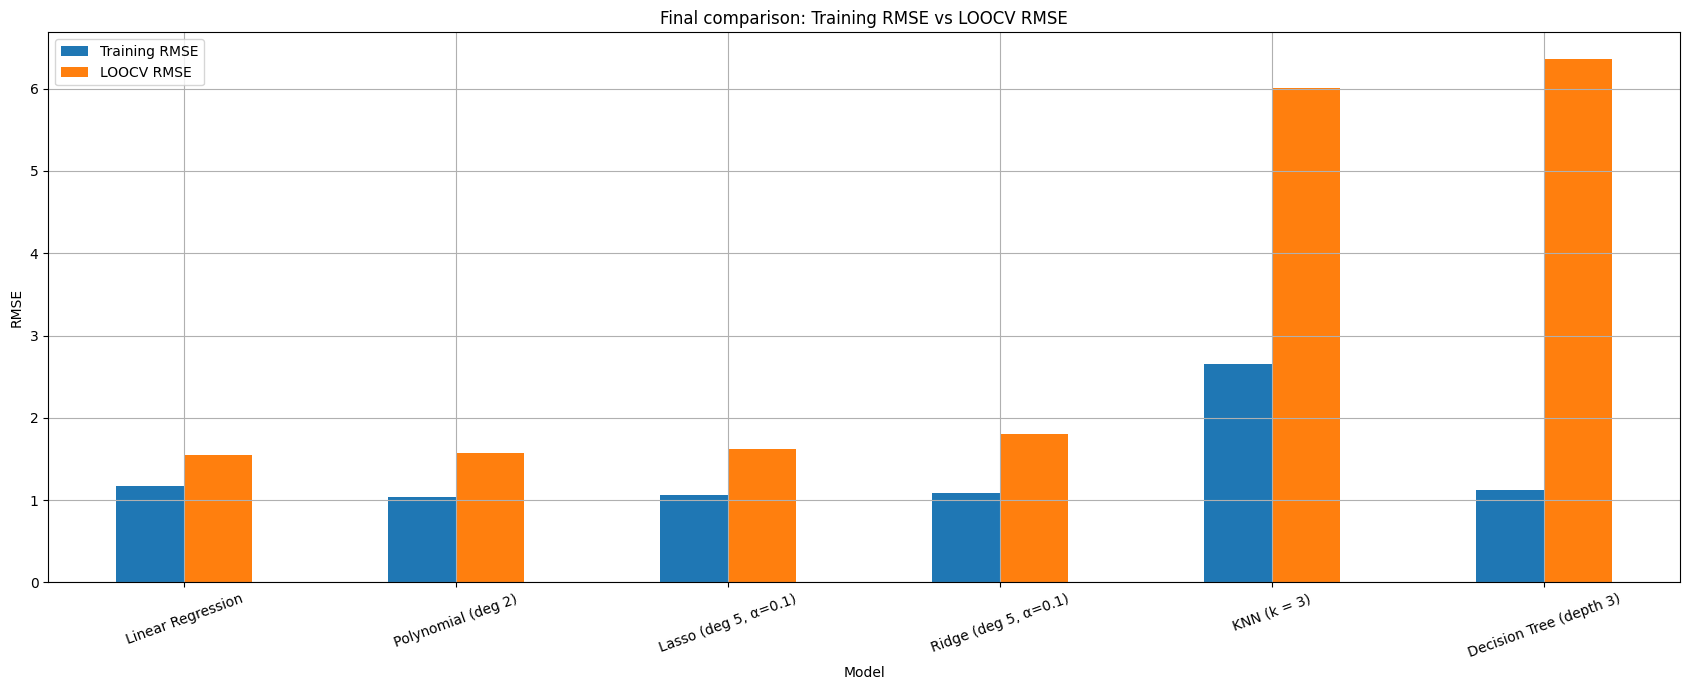

In [72]:
final_table.plot(
    x="Model", y=["Training RMSE", "LOOCV RMSE"],
    kind="bar", figsize=(17, 7), grid=True, rot=20,
    title="Final comparison: Training RMSE vs LOOCV RMSE",
    ylabel="RMSE"
)
plt.tight_layout()
plt.show()

* For the four linear-type models the training and LOOCV bars are **short and close**
* good balance, For KNN and the Decision Tree the LOOCV bar is **much taller** than the training bar: poor generalization.

# Conclusion

All models were evaluated on the same dataset with the same strategy (LOOCV).Preprocessing was done inside a `Pipeline` to avoid data leakage.

**1) - Model complexity.**
- Training RMSE decreases as the polynomial degree increases (1.17 at degree 1, 0.0002 at degree 9)
  - while LOOCV RMSE increases (1.55, 1.57, 2.06, 3.71, **261.91**). 
- A more complex model fits the training data better but generalizes worse: this is overfitting. The best degree is 1, since the data is almost linear.

**2) Feature representation.**
- Adding `x², x³` (LOOCV 2.06) or up to `x⁵` (3.71) makes generalization worse than the original feature `x` (1.55)
  - even though the training RMSE improves.
- Richer features only help when the data needs them. Tree (depth 1) underfits (R² = 0.75)
  - while Tree (depth 3) and KNN overfit (LOOCV 6.37 and 6.00).

**3) Regularization.**
- Ridge and Lasso improve the degree-5 polynomial a lot: LOOCV RMSE drops from 3.71 to **1.81** (Ridge) and **1.62** (Lasso) with alpha = 0.1.
- Alpha must be tuned, because alpha = 10 leads to underfitting. Regularization does not beat the simple linear model (1.55).

**4) Best balance.** **Linear Regression** is the best model:
- lowest LOOCV RMSE (**1.5486**) and smallest gap between training and LOOCV error (0.38).

- **Overall:** the best model is the one whose complexity matches the structure of the data.
- Here the relationship is near-linear
  - so a simple model generalizes best, and regularization mainly serves to control overly complex models.